# Lab 3 - Part 2: Fine-tuning AraGPT2
Run on Kaggle with Internet ON and GPU T4. Add the Lab 3 Kaggle Dataset as input.


In [17]:
import random, re, math
from pathlib import Path
import numpy as np, pandas as pd, torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

exact_path = Path('/kaggle/input/datasets/kaddarmohamediliass/raw-dataset/raw_articles .csv')
cands = [exact_path] if exact_path.is_file() else []
cands += list(Path('/kaggle/input').glob('**/raw_articles*.csv')) if Path('/kaggle/input').exists() else []
cands += list(Path('/kaggle/working').glob('**/raw_articles*.csv')) + list(Path.cwd().glob('**/data/raw_articles*.csv'))

raw_path = next((p for p in cands if p.is_file()), None)
if raw_path is None:
    raise FileNotFoundError('Run Part 1 or add raw_articles.csv as Kaggle Dataset input.')

raw = pd.read_csv(raw_path)
print('Device:', DEVICE, '|', raw_path)
print(raw.head())

Device: cuda | /kaggle/input/datasets/kaddarmohamediliass/raw-dataset/raw_articles .csv
                                                 url     source section  \
0               https://www.aljazeera.net/video/live  aljazeera   sport   
1               https://www.aljazeera.net/dimensions  aljazeera   sport   
2  https://www.aljazeera.net/sport/2026/11/21/10-...  aljazeera   sport   
3  https://www.aljazeera.net/sport/2026/11/21/%d8...  aljazeera   sport   
4  https://www.aljazeera.net/sport/2026/11/20/%d9...  aljazeera   sport   

                                               title  \
0                                  البث الحي المباشر   
1                                              ميدان   
2  10 هجمات سيبرانية لا ينساها تاريخ الرياضة العا...   
3  بالفيديو.. ديميرال يغرس علم الأهلي في ملعب الن...   
4  صغار المحاربين.. منتخب الجزائر لمحو الخيبة في ...   

                                                text  date_published  \
0  قد يحتوي هذا الفيديو أنماطا ضوئية أو صورا يمكن...

In [18]:
import subprocess,sys
subprocess.run([sys.executable,'-m','pip','install','-q','transformers','datasets','arabert','sacrebleu','accelerate'],check=False)
from transformers import AutoTokenizer,AutoModelForCausalLM
MODEL='aubmindlab/aragpt2-base'
tok=AutoTokenizer.from_pretrained(MODEL); base=AutoModelForCausalLM.from_pretrained(MODEL).to(DEVICE)
if tok.pad_token is None: tok.pad_token=tok.eos_token
print('Loaded',MODEL)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: aubmindlab/aragpt2-base
Key                         | Status     |  | 
----------------------------+------------+--+-
h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded aubmindlab/aragpt2-base


In [19]:
from arabert.preprocess import ArabertPreprocessor
prep=ArabertPreprocessor(model_name=MODEL)
def clean(x):
    x=re.sub(r'https?\S+|www\.\S+|<[^>]+>',' ',str(x)); return re.sub(r'\s+',' ',x).strip()
football=raw.dropna(subset=['text']).copy()
if 'score' in football: football=football[football.score>=6].copy()
football['text']=football.text.map(clean); football=football[football.text.str.split().str.len().between(50,250)].drop_duplicates('text').head(1500)
football['encoded']=football.text.map(lambda x:prep.preprocess(x)+tok.eos_token)
n=int(.9*len(football)); train_text=football.encoded.iloc[:n].tolist(); held=football.encoded.iloc[n:].tolist()
print('Articles:',len(football),'train:',len(train_text),'held-out:',len(held)); print(football.text.head())


Articles: 85 train: 76 held-out: 9
1    اعتاد نتنياهو الاستعانة بالخرائط والرسوم والصو...
3    وقت القراءة: دقيقتان التركي ديميرال يغرس علم ا...
5    وقت القراءة: دقيقتان أعلن نادي أيك أثينا أنه س...
8    وقت القراءة: دقيقتان المنتخب المغربي يصل إلى ا...
9    وقت القراءة: دقيقة واحدة يعد عمدة نيويورك زهرا...
Name: text, dtype: object


In [20]:
from torch.utils.data import Dataset,DataLoader
BLOCK=256
def make_blocks(texts):
    ids=[]
    for x in texts: ids.extend(tok(x,add_special_tokens=False).input_ids)
    ids=ids[:len(ids)-len(ids)%BLOCK]; return torch.tensor(ids).view(-1,BLOCK)
TB,VB=make_blocks(train_text),make_blocks(held)
class CausalDS(Dataset):
    def __init__(self,b): self.b=b
    def __len__(self): return len(self.b)
    def __getitem__(self,i):
        x=self.b[i]; return {'input_ids':x,'attention_mask':torch.ones_like(x),'labels':x.clone()}
tl,vl=DataLoader(CausalDS(TB),batch_size=4,shuffle=True),DataLoader(CausalDS(VB),batch_size=4)
print('Train blocks:',TB.shape,'Validation blocks:',VB.shape)


Train blocks: torch.Size([88, 256]) Validation blocks: torch.Size([12, 256])


In [22]:
prompts=['فاز المنتخب المغربي على','أعلن النادي رسميا عن التعاقد مع','في مباراة قوية انتهت بالتعادل بين','صرح المدرب بعد المباراة أن','تأهل الفريق إلى نهائي دوري أبطال','تصدر الفريق جدول الترتيب بعد','سجل اللاعب هدفا رائعا في الدقيقة','استعدادا لكأس العالم يخوض المنتخب']

def generate(model, prompt, strategy='top_p'):
    clean_prompt = prep.preprocess(prompt)
    x = tok(clean_prompt, return_tensors='pt').to(DEVICE)
    kw = {'max_length': 160, 'pad_token_id': tok.eos_token_id, 'repetition_penalty': 1.2, 'no_repeat_ngram_size': 3}
    if strategy == 'greedy': kw['do_sample'] = False
    elif strategy == 'beam': kw.update(do_sample=False, num_beams=5, early_stopping=True)
    elif strategy == 'top_k': kw.update(do_sample=True, top_k=50, temperature=.8)
    else: kw.update(do_sample=True, top_p=.92, temperature=.8)
    return tok.decode(model.generate(**x, **kw)[0], skip_special_tokens=True)

base.eval()
base_outputs = {p: generate(base, p, 'top_p') for p in prompts}
print(base_outputs[prompts[0]])

فاز المنتخب المغربي على ضيفه منتخب الطوغو بهدف نظيف في المباراة التي جمعت بينهما مساء اليوم الجمعة ، ضمن الجولة الخامسة قبل الأخيرة من المجموعة الثانية بالتصفيات المؤهلة لكأس أمم إفريقيا 2019 بالكاميرون .وافتتح اللاعب يونس بلهندة التسجيل للمنتخب المغربي ( ق 16 ) بالدقيقة 18 بعد كرة مرفوعة من فوق الحارس ثم أضاف زميله خالد بوطيب الهدف الثاني ( ق 19 ) .وأهدر أسود الأطلس ركلة جزاء بعد مرور 5 دقائق عندما نفذ عادل رامي ركلة الجزاء بنجاح . وفي الشوط الأول من اللقاء تابع أصحاب الأرض هجماتهم عبر الثلاثي حكيم زياش وغازي طارق و كريم الأحمدي فيما اعتمد رفاق يوسف النصيري على الكرات الثابتة حتى نهاية هذا الشوط بالتعادل السلبي بدون أهداف .وفي الشوط الثاني عزز رشيد غزال تقدم الأسود بالهدف الثالث إثر تمريرة من المهاجم محمد أوناجم داخل منطقة العمليات .أهلا وسهلا بك زائرنا الكريم ,


In [23]:
from transformers import get_linear_schedule_with_warmup
model=AutoModelForCausalLM.from_pretrained(MODEL).to(DEVICE); model.gradient_checkpointing_enable()
opt=torch.optim.AdamW(model.parameters(),lr=5e-5,weight_decay=.01)
steps = len(tl) * 3
sched=get_linear_schedule_with_warmup(opt,max(1,int(.1*steps)),steps)
train_losses=[]; val_losses=[]
for epoch in range(1,4):
    model.train(); ls=[]
    for i,b in enumerate(tl):
        b={k:v.to(DEVICE) for k,v in b.items()}; opt.zero_grad(); loss=model(**b).loss; loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1); opt.step(); sched.step(); ls.append(loss.item())
        if i%20==0: print('Epoch',epoch,'step',i,'loss',round(loss.item(),4))
    model.eval(); vls=[]
    with torch.no_grad():
        for b in vl:
            b={k:v.to(DEVICE) for k,v in b.items()}; vls.append(model(**b).loss.item())
    a,b=float(np.mean(ls)),float(np.mean(vls)); train_losses.append(a); val_losses.append(b)
    print('Epoch',epoch,'train_loss',round(a,4),'val_loss',round(b,4),'perplexity',round(math.exp(b),2))


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: aubmindlab/aragpt2-base
Key                         | Status     |  | 
----------------------------+------------+--+-
h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1 step 0 loss 8.6279
Epoch 1 step 20 loss 6.2013
Epoch 1 train_loss 6.6659 val_loss 5.3085 perplexity 202.05
Epoch 2 step 0 loss 5.9946
Epoch 2 step 20 loss 5.6363
Epoch 2 train_loss 5.6552 val_loss 5.2508 perplexity 190.73
Epoch 3 step 0 loss 5.4047
Epoch 3 step 20 loss 5.5114
Epoch 3 train_loss 5.3759 val_loss 5.2444 perplexity 189.5


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved: /kaggle/working/aragpt2-football


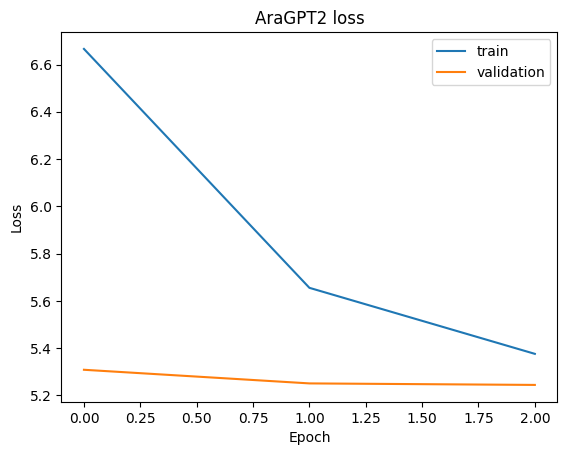

                              Prompt  \
0            فاز المنتخب المغربي على   
1    أعلن النادي رسميا عن التعاقد مع   
2  في مباراة قوية انتهت بالتعادل بين   
3         صرح المدرب بعد المباراة أن   
4   تأهل الفريق إلى نهائي دوري أبطال   
5       تصدر الفريق جدول الترتيب بعد   
6   سجل اللاعب هدفا رائعا في الدقيقة   
7  استعدادا لكأس العالم يخوض المنتخب   

                                              Before  \
0  فاز المنتخب المغربي على ضيفه منتخب الطوغو بهدف...   
1  أعلن النادي رسميا عن التعاقد مع المدرب الهولند...   
2  في مباراة قوية انتهت بالتعادل بين الفريقين ، ل...   
3  صرح المدرب بعد المباراة أن التعادل سيكون ايجاب...   
4  تأهل الفريق إلى نهائي دوري أبطال آسيا لكرة الق...   
5  تصدر الفريق جدول الترتيب بعد تغلبه على نظيره ف...   
6  سجل اللاعب هدفا رائعا في الدقيقة 24 ، عندما اس...   
7  استعدادا لكأس العالم يخوض المنتخب الالماني مبا...   

                                               After  
0  فاز المنتخب المغربي على نظيره البرتغالي بهدف ن...  
1  أعلن النادي رسميا عن 

In [24]:
import matplotlib.pyplot as plt
save=Path('/kaggle/working/aragpt2-football') if Path('/kaggle/working').exists() else Path.cwd()/'aragpt2-football'
model.save_pretrained(save); tok.save_pretrained(save); print('Saved:',save)
plt.plot(train_losses,label='train'); plt.plot(val_losses,label='validation'); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.title('AraGPT2 loss'); plt.show()
model.eval(); rows=[{'Prompt':p,'Before':base_outputs[p],'After':generate(model,p,'top_p')} for p in prompts]
print(pd.DataFrame(rows))


In [25]:
def perplexity(m,loader):
    m.eval(); ls=[]
    with torch.no_grad():
        for b in loader:
            b={k:v.to(DEVICE) for k,v in b.items()}; ls.append(m(**b).loss.item())
    x=float(np.mean(ls)); return x,math.exp(x)
bl,bp=perplexity(base,vl); fl,fp=perplexity(model,vl)
print(pd.DataFrame({'Model':['Base AraGPT2','Fine-tuned AraGPT2'],'Loss':[bl,fl],'Perplexity':[bp,fp]}))


                Model      Loss  Perplexity
0        Base AraGPT2  4.413953   82.595357
1  Fine-tuned AraGPT2  5.244415  189.504916


In [26]:
from sacrebleu.metrics import BLEU

def generate_continuation(model, prompt):
    clean_prompt = prep.preprocess(prompt)
    x = tok(clean_prompt, return_tensors='pt').to(DEVICE)
    in_len = x['input_ids'].shape[1]
    kw = {
        'max_new_tokens': 80,
        'pad_token_id': tok.eos_token_id,
        'repetition_penalty': 1.2,
        'no_repeat_ngram_size': 3,
        'do_sample': True,
        'top_p': 0.92,
        'temperature': 0.8
    }
    out_ids = model.generate(**x, **kw)[0][in_len:]  # Only keep newly generated tokens
    return tok.decode(out_ids, skip_special_tokens=True)

refs = []; base_out = []; fine_out = []
held_text = football.text.iloc[n:].tolist()

for article in held_text[:50]:
    norm_art = prep.preprocess(article)
    words = norm_art.split()
    if len(words) < 15: continue
    prompt = ' '.join(words[:10])
    ref = ' '.join(words[10:60])
    if not ref: continue
    refs.append(ref)
    base_out.append(generate_continuation(base, prompt))
    fine_out.append(generate_continuation(model, prompt))

b = BLEU(effective_order=True)
print('Base BLEU:', b.corpus_score(base_out, [refs]).score)
print('Fine-tuned BLEU:', b.corpus_score(fine_out, [refs]).score)
print('Open-ended BLEU is naturally low; compare relative improvement and qualitative fluency.')

Base BLEU: 0.4706950006745131
Fine-tuned BLEU: 0.5948678834221418
Open-ended BLEU is naturally low; compare relative improvement and qualitative fluency.
